**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5061.10 - Operaciones de aprendizaje automático**

Tecnológico de Monterrey

Dr. Iván Resyes Amezcua  
Alejandro Fortoul Diaz

**Semana 4**
Módulo 2: Mejores prácticas

Actividad Individual | Código de experimentación base con MLFlow
---

*   **NOMBRE:** Ángel Alexis Anaya Alamea
*   **MATRÍCULA:** A01741351

## **1. Entendimiento del conjunto de datos**

El siguiente conjunto de datos fue obtenido de [Kaggle](https://www.kaggle.com/datasets/yasserh/titanic-dataset). Contiene información relacionada con el hundimiento del **Titanic**, tras colisionar con un iceberg. Durante este accidente, 1502 de 2224 pasajeros y tripulantes murieron. Si bien la suerte influyó en cierta medida en la supervivencia, se tiene la hipótesis de que algunos grupos de personas tenían más probabilidades de sobrevivir que otros.

El proyecto comprende las etapas de análisis exploratorio de datos (EDA), limpieza y preparación de los datos, entrenamiento de un modelo baseline, evaluación de su desempeño y registro del experimento mediante MLflow.

Finalmente, se analizarán oportunidades de mejora desde una perspectiva de MLOps, considerando aspectos como reproducibilidad, seguimiento de experimentos, automatización, validación de datos y monitoreo del modelo.


In [3]:
# Importación de librerías base
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, 
                            confusion_matrix, roc_auc_score, average_precision_score,
                            classification_report, confusion_matrix, roc_curve, precision_recall_curve)

import mlflow
import mlflow.sklearn

from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

In [4]:
# Carga de datos
titanic_df = pd.read_csv('../data/raw/Titanic-Dataset.csv')

# Descripción de la estructura
print(f"   * Número de registros: {titanic_df.shape[0]}")
print(f"   * Número de variables: {titanic_df.shape[1]}\n")
print("   * Información de las variables y tipos de datos:")
titanic_df.info()

print("\n   * Primeros registros:")
display(titanic_df.head())

   * Número de registros: 891
   * Número de variables: 12

   * Información de las variables y tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB

   * Primeros registros:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


La estructura general del dataset de Titanic es la siguiente:
- El dataset contiene exactamente 891 registros (entradas del 0 al 890).  
- El número total de variables es de 12.   
- Los tipos de datos generales se componen de 2 variables float64, 5 variables int64 y 5 variables tipo object.    

A continuación, se detalla la información y el nivel de completitud de cada variable, lo cual será fundamental para el paso de limpieza de datos:
* **PassengerId**: 891 valores no nulos, tipo de dato int64. (Identificador único del pasajero).   
* **Survived**: 891 valores no nulos, tipo de dato int64. (Variable objetivo, 0 = No, 1 = Sí).   
* **Pclass**: 891 valores no nulos, tipo de dato int64. (Clase del pasajero).   
* **Name**: 891 valores no nulos, tipo de dato object. (Nombre del pasajero).   
* **Sex**: 891 valores no nulos, tipo de dato object. (Sexo del pasajero).
* **Age**: 714 valores no nulos, tipo de dato float64. (Edad del pasajero).   
* **SibSp**: 891 valores no nulos, tipo de dato int64. (Número de hermanos/cónyuges a bordo).   
* **Parch**: 891 valores no nulos, tipo de dato int64. (Número de padres/hijos a bordo).   
* **Ticket**: 891 valores no nulos, tipo de dato object. (Número de ticket).   
* **Fare**: 891 valores no nulos, tipo de dato float64. (Tarifa pagada).  
* **Cabin**: 204 valores no nulos, tipo de dato object. (Número de cabina).   
* **Embarked**: 889 valores no nulos, tipo de dato object. (Puerto de embarque).



De estas variables y los tipos de datos que fueron interpretados al momento de leer la base de datos, se tiene que particularmente 3 son leídas como numéricas cuando son semánticamente categóricas: `PassengerId`, `Survived` y `Pclass`.

## **2. Análisis exploratorio de datos**

### 2.1. Tipos de datos, valores faltantes, duplicados y distribuciones generales

In [5]:
# Corrección de tipos de datos
titanic_df['Pclass'] = titanic_df['Pclass'].astype('category')
titanic_df['Survived'] = titanic_df['Survived'].astype('category')
titanic_df['PassengerId'] = titanic_df['PassengerId'].astype(str)

In [6]:
# Se hace una lista de variables numéricas y otra de categóricas
num_cols = titanic_df.select_dtypes(include=['number']).columns.tolist()
print(f"Columnas numéricas: {num_cols}")
cat_cols = titanic_df.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"Columnas categóricas: {cat_cols}")

Columnas numéricas: ['Age', 'SibSp', 'Parch', 'Fare']
Columnas categóricas: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


C:\Users\hp\AppData\Local\Temp\ipykernel_18856\2945844312.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = titanic_df.select_dtypes(include=['object', 'category']).columns.tolist()


In [7]:
col_target = 'Survived'
col_id = 'PassengerId'

In [8]:
# Validación de nulos
print("   * Validación de valores nulos: ")
display(titanic_df.isna().sum())

   * Validación de valores nulos: 


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
print("   * Resumen de las variables numéricas: ")
resumen_num_titanic_df = titanic_df.describe().T
resumen_num_titanic_df

   * Resumen de las variables numéricas: 


,count,mean,std,min,25%,50%,75%,max
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [10]:
print("   * Resumen de las variables categóricas: ")
resumen_cat_titanic_df = titanic_df.describe(include=['object', 'category']).T
resumen_cat_titanic_df

   * Resumen de las variables categóricas: 


C:\Users\hp\AppData\Local\Temp\ipykernel_18856\444080463.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  resumen_cat_titanic_df = titanic_df.describe(include=['object', 'category']).T


,count,unique,top,freq
PassengerId,891,891,1,1
Survived,891,2,0,549
Pclass,891,3,3,491
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


In [11]:
# Recuento de cada categoría única en las variables categóricas
for column in cat_cols:
    print(titanic_df[column].value_counts(dropna = False))
    print('-' * 50)

PassengerId
1      1
2      1
3      1
4      1
5      1
      ..
887    1
888    1
889    1
890    1
891    1
Name: count, Length: 891, dtype: int64
--------------------------------------------------
Survived
0    549
1    342
Name: count, dtype: int64
--------------------------------------------------
Pclass
3    491
1    216
2    184
Name: count, dtype: int64
--------------------------------------------------
Name
Braund, Mr. Owen Harris                                1
Cumings, Mrs. John Bradley (Florence Briggs Thayer)    1
Heikkinen, Miss. Laina                                 1
Futrelle, Mrs. Jacques Heath (Lily May Peel)           1
Allen, Mr. William Henry                               1
                                                      ..
Montvila, Rev. Juozas                                  1
Graham, Miss. Margaret Edith                           1
Johnston, Miss. Catherine Helen "Carrie"               1
Behr, Mr. Karl Howell                                  1
Dooley, M

**Análisis de variables numéricas:**
* Valores faltantes: La variable `Age` presenta solo 714 registros frente a los 891 totales, por lo que será necesario definir una estrategia de imputación de estos datos faltantes.
* Asimetría y Outliers: `Fare` muestra un sesgo extremo hacia la derecha; el 75% de los boletos costó 31.0 o menos, pero el valor máximo se dispara hasta 512.32. Si no aplicamos transformaciones o escaladores robustos, estos valores atípicos podrían afectar los resultados de los modelos.   

**Análisis de variables categóricas:**
* Desbalance del Target: En `Survived`, la clase dominante es 0 (no sobrevivió) con 549 apariciones. Derivado de esto, la métrica de `Accuracy` podría ser engañoso, por lo que priorizaremos el F1-Score, la PR-AUC y las matrices de confusión en MLflow.   
* Ruido por alta cardinalidad: `PassengerId`, `Name` tiene 891 valores únicos y `Ticket` 681. Estas variables aportarán ruido al baseline, por lo que deberán excluirse.   
* Degradación por datos faltantes: `Cabin` apenas cuenta con 204 registros no nulos: inyectar una variable con ~77% de datos faltantes en una primera iteración agrega complejidad innecesaria sin garantizar qu el modelo vaya a tener un mejor desempeño.

In [12]:
# RREGISTROS DUPLICADOS
duplicados = titanic_df[titanic_df.duplicated(keep=False)]
print(f"Se encontraron {len(duplicados)} registros duplicados.")

Se encontraron 0 registros duplicados.


### 2.2. Análisis univariado

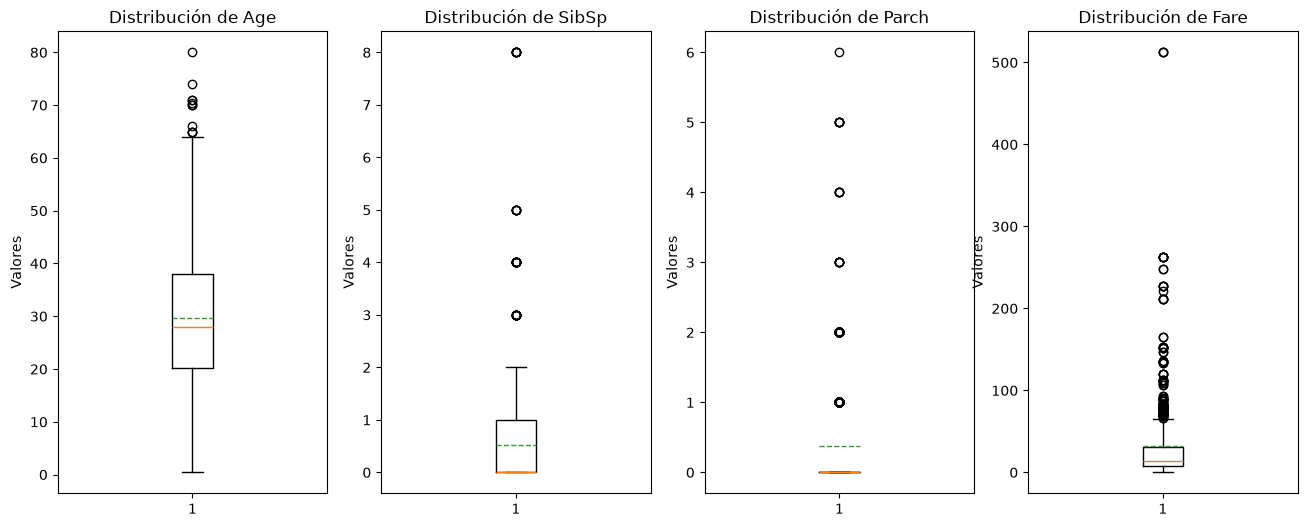

In [13]:
fig, axes = plt.subplots(nrows = 1, ncols = 4, figsize = (16, 6))

# Iteraciones para crear cada boxplot. Se usa .dropna() para eliminar datos faltantes y que se pueda graficar.
for ax, col in zip(axes.flatten(), num_cols):
    ax.boxplot(titanic_df[col].dropna(), showmeans = True, meanline = True)
    ax.set_title(f'Distribución de {col}')
    ax.set_ylabel('Valores')

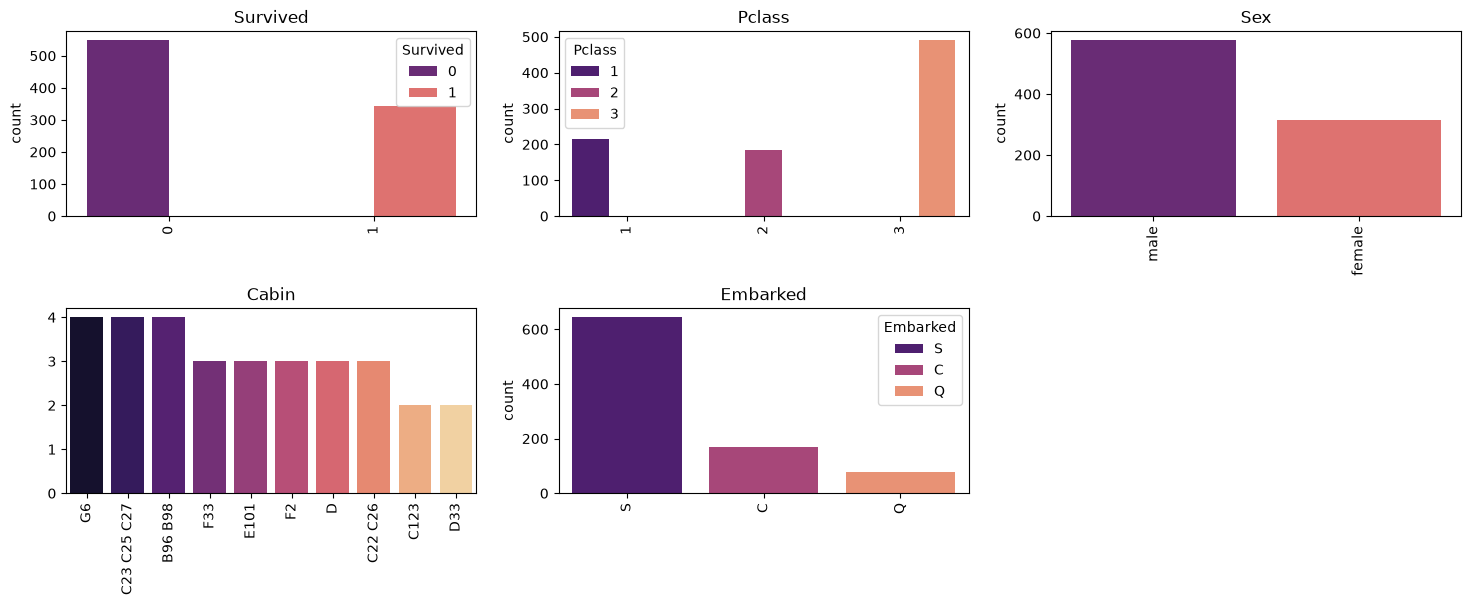

In [14]:
# Para las gráficas de las variables categóricas se van a excluir aquellas que tienen alta cardinalidad:
variables_cat_a_excluir_graficas = ['PassengerId', 'Name', 'Ticket']
cat_cols_graficas = [col for col in cat_cols if col not in variables_cat_a_excluir_graficas]

fig, axes = plt.subplots(2,3, figsize=(18,6))
plt.subplots_adjust(hspace=0.5)
axes = axes.ravel()
for col, ax in zip(titanic_df[cat_cols_graficas], axes):
  if titanic_df[col].nunique() > 10:

    counts = titanic_df[col].value_counts()
    top_10 = counts.head(10)
    sns.barplot(x = top_10.index, y = top_10.values, hue = top_10.index, palette = "magma", ax = ax)
    ax.set(title =f'{col}', xlabel = None)
    ax.tick_params(axis = 'x',rotation = 90)

  else:
    sns.countplot(x = titanic_df[col], hue = titanic_df[col], palette = "magma", ax=ax)
    ax.set(title =f'{col}', xlabel = None)
    ax.tick_params(axis = 'x',rotation = 90)

fig.delaxes(axes[-1])

**Análisis de variables numéricas:**
* Comportamiento de Edad (Age): Más allá de requerir imputación, el diagrama de caja revela que la edad tiene una mediana cercana a los 28 años, con presencia de valores atípicos (outliers) en el extremo superior correspondientes a adultos mayores. Esta distribución puede justificar el hecho de que la imputación se realice con la mediana para no sesgar el modelo.
* Dispersión en acompañantes (SibSp y Parch): Ambas variables muestran una concentración masiva en el valor 0 (la mayoría viajaba sin familiares), pero presentan colas de valores atípicos que llegan hasta 8 en SibSp y 6 en Parch.

**Análisis de variables categóricas:**
* Entedimiento de las distribuciones base: Los conteos revelan el perfil demográfico dominante del dataset: la gran mayoría de los pasajeros son hombres, viajan en tercera clase (Pclass 3) y embarcaron en el puerto de Southampton (S).
* Conocer este tipo de distribuciones son importantes ya que, si en futuro este proyecto entrara a producción, se esperaría recibir peticiones con las mismas distribuciones, en caso contrario, se presentaría *Data Drift*.


### 2.3. Análisis bivariado

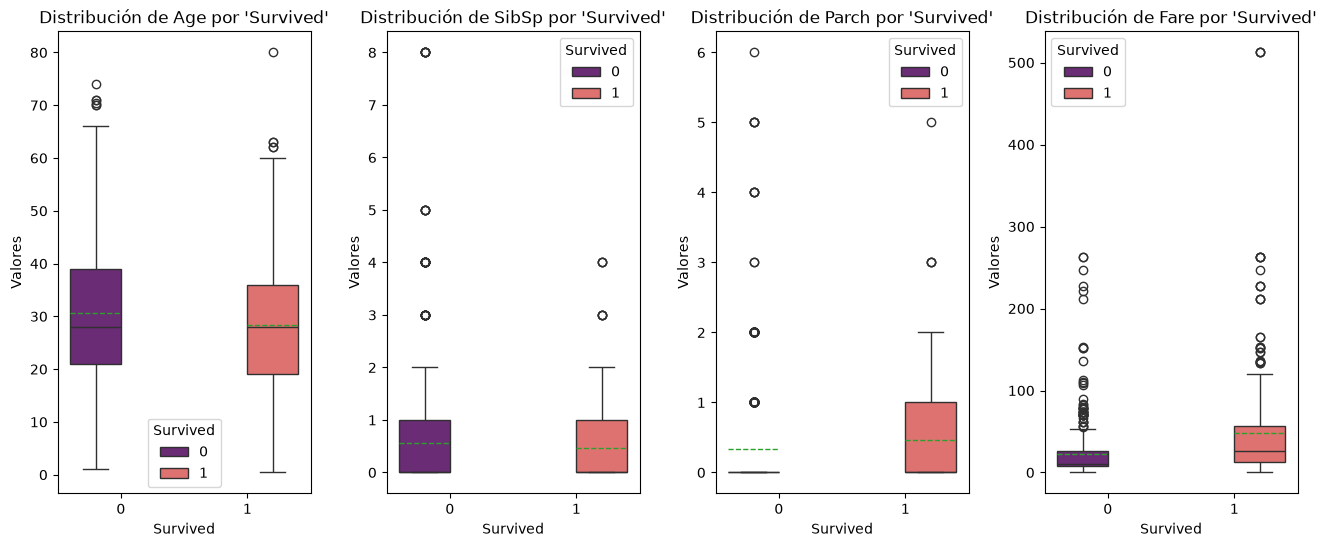

In [15]:
# ANÁLISIS DE VARIABLES NUMÉRICAS
fig, axes = plt.subplots(nrows = 1, ncols = 4, figsize = (16, 6))
plt.subplots_adjust(wspace = 0.3, hspace = 0.4)

# Iteraciones para crear cada boxplot
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(data = titanic_df, x = 'Survived', y = col, showmeans = True, meanline = True, hue = 'Survived', palette = "magma", ax = ax)
    ax.set_title(f"Distribución de {col} por 'Survived'")
    ax.set_ylabel('Valores')



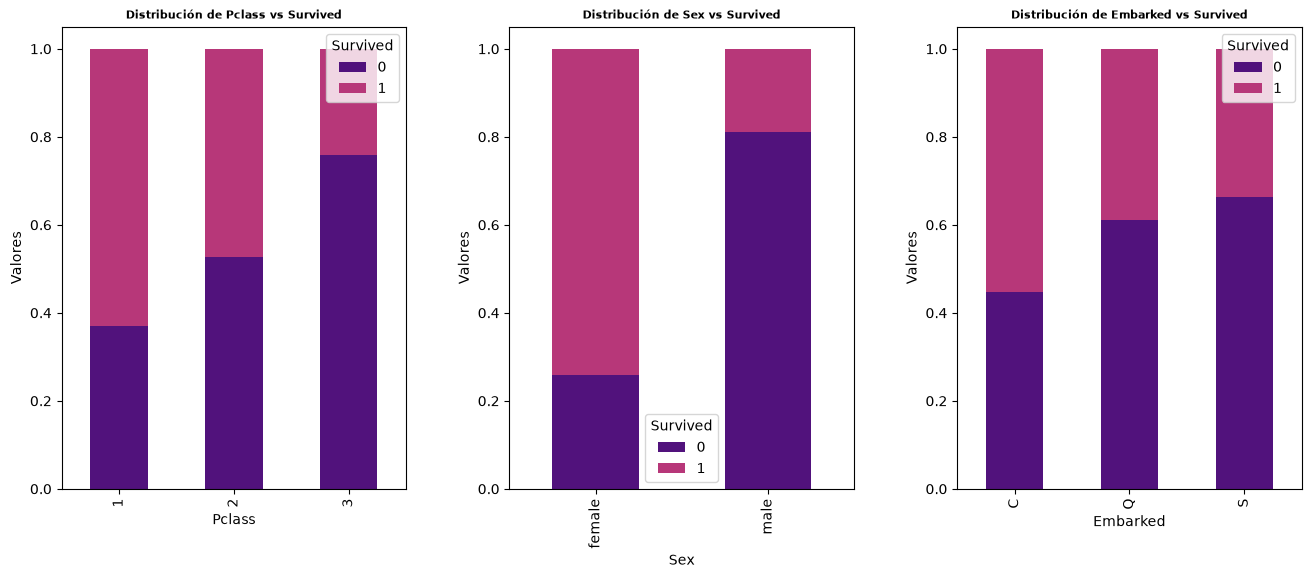

In [16]:
fig, axes = plt.subplots(nrows = 1, ncols = 3, figsize = (16, 6))
plt.subplots_adjust(wspace = 0.3, hspace = 0.4)
cat_cols_graficas_2 = [col for col in cat_cols_graficas if col not in ['Survived', 'Cabin']]

paleta_colores = sns.color_palette("magma", 3)

# Iteraciones para crear cada boxplot
for ax, col in zip(axes.flatten(), cat_cols_graficas_2):
    pd.crosstab(titanic_df[col], titanic_df['Survived'], normalize = 'index').plot(kind = 'bar', stacked = True, color = paleta_colores, ax = ax)
    ax.set_title(f"Distribución de {col} vs Survived",
                  fontsize = 8,
                  fontweight = 'bold',
                  loc = 'center')
    ax.set_ylabel('Valores')

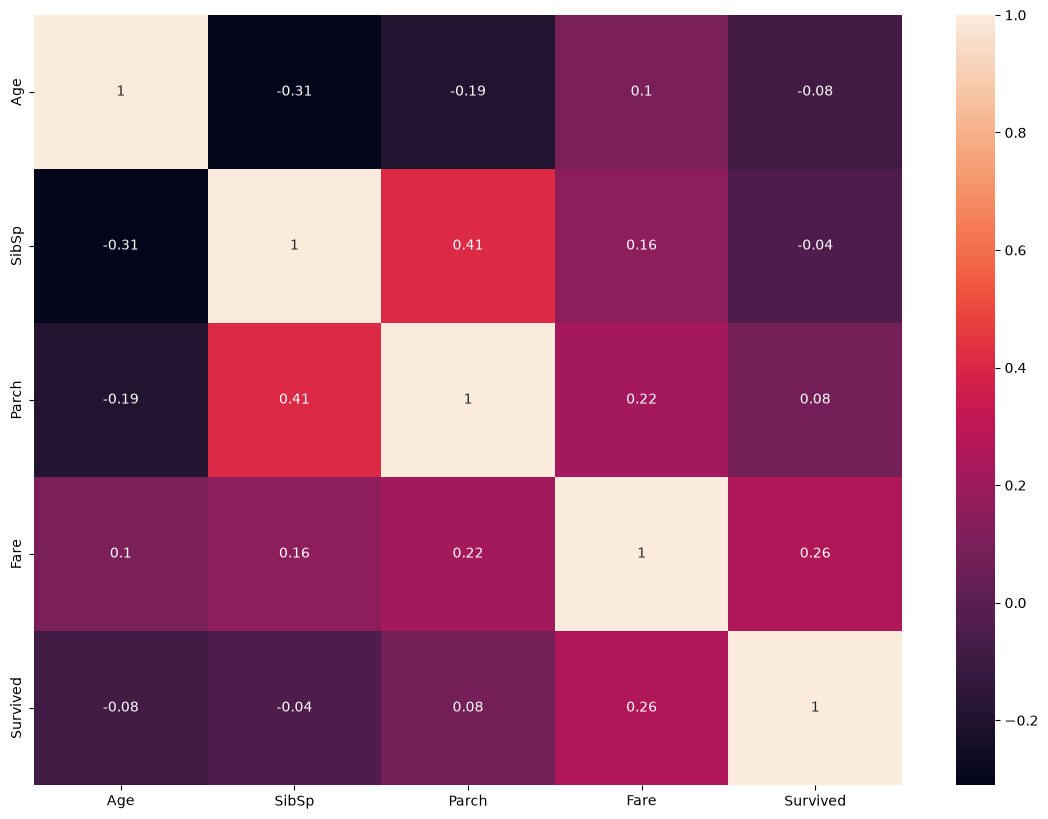

In [17]:
# ANÁLISIS DE CORRELACIÓN
# Calculamos la correlación de Pearson
corr_matrix = titanic_df[num_cols + [col_target]].corr()

# Heatmap
plt.figure(figsize = (14, 10))
sns.heatmap(round(corr_matrix,2), annot = True)
plt.show()

Primeros hallazgos del Análisis Exploratorio de Datos (EDA)

- **Poder predictivo de variables demográficas y socioeconómicas:** Las gráficas de proporción revelan que el género y la clase social son los determinantes principales de supervivencia: las mujeres y los pasajeros de primera clase (Pclass 1) presentan tasas de supervivencia drásticamente superiores a los hombres y pasajeros de tercera clase. De igual forma, los pasajeros que embarcaron en Cherbourg (C) muestran una mayor proporción de supervivencia.   
- **Correlaciones lineales y multicolinealidad:** El mapa de calor muestra que la correlación lineal directa más fuerte con la variable objetivo (Survived) es la tarifa (Fare) con apenas un 0.26. La ausencia de relaciones lineales fuertes con el target sugiere que los modelos puramente lineales tendrán un límite de desempeño. Por otro lado, la correlación positiva moderada de 0.41 entre SibSp y Parch nos dice empíricamente que se podría combinar ambas columnas en una sola variable llamada "Tamaño de Familia" para reducir la dimensionalidad y el ruido.   
- **Distribuciones y valores atípicos:** Los diagramas de caja evidencian que los sobrevivientes tienen una mediana de edad ligeramente inferior a los no sobrevivientes. En cuanto a las variables familiares, los sobrevivientes presentan una ligera dispersión positiva en Parch (padres/hijos), mientras que la gran mayoría de los no sobrevivientes se concentran en el valor 0 tanto para Parch como para SibSp